# Preparación de datasets

Cada registro del dataset consta de una secuencia de 6 "frames". 

Cada frame es una imagen de radar con varias variables. 

La estrategia se resume en ventanas deslizantes sobre todos los eventos con ≥ 8 frames (reales, con contexto previo/posterior si lo tenés), split por evento estratificado por duración, WeightedRandomSampler con peso 1/sqrt(n_ventanas_evento), y devolver event_id para analizar métricas por tipo de evento.

In [1]:
from netCDF4 import Dataset
import glob ## listar archivos de una carpeta
import pyart ## libreria para procesar datos de radar

import sys
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.func_basicas import (calcular_zdr,
                              suavizar_campo,
                              calcular_kdp,
                              calcular_pp_mati,
                              get_nearest_gate_azimuth)


## You are using the Python ARM Radar Toolkit (Py-ART), an open source
## library for working with weather radar data. Py-ART is partly supported
## by the U.S. Department of Energy Office of Science as part of
## the Atmospheric Radiation Measurement (ARM) User Facility.
##
## If you use this software to prepare a publication, please cite:
##
##     JJ Helmus and SM Collis, JORS 2016, doi: 10.5334/jors.119



In [2]:
radar_list = '/opt/backups-operativos/usuarios/anaalabi/nowcasting_radar/data/incoming/2019/01/02_03/RMA1_0301*.nc'
radar_list = glob.glob(radar_list)
radar_list.sort()
radar_list

['/opt/backups-operativos/usuarios/anaalabi/nowcasting_radar/data/incoming/2019/01/02_03/RMA1_0301_01_20190102T180250Z.nc',
 '/opt/backups-operativos/usuarios/anaalabi/nowcasting_radar/data/incoming/2019/01/02_03/RMA1_0301_01_20190102T181104Z.nc',
 '/opt/backups-operativos/usuarios/anaalabi/nowcasting_radar/data/incoming/2019/01/02_03/RMA1_0301_01_20190102T190610Z.nc',
 '/opt/backups-operativos/usuarios/anaalabi/nowcasting_radar/data/incoming/2019/01/02_03/RMA1_0301_01_20190102T191425Z.nc',
 '/opt/backups-operativos/usuarios/anaalabi/nowcasting_radar/data/incoming/2019/01/02_03/RMA1_0301_01_20190102T192240Z.nc',
 '/opt/backups-operativos/usuarios/anaalabi/nowcasting_radar/data/incoming/2019/01/02_03/RMA1_0301_01_20190102T193054Z.nc',
 '/opt/backups-operativos/usuarios/anaalabi/nowcasting_radar/data/incoming/2019/01/02_03/RMA1_0301_01_20190102T193909Z.nc',
 '/opt/backups-operativos/usuarios/anaalabi/nowcasting_radar/data/incoming/2019/01/02_03/RMA1_0301_01_20190102T200446Z.nc',
 '/opt/b

In [3]:
## Leo el archivo de radar
radar_file = pyart.io.read(radar_list[0])

## Listar variables

radar_file.fields.keys()

## Explorar variable
radar_file.fields['DBZH']['data'].data

## notar que las dimensiones de radar_file.fields['DBZH']['data'] es (alfa, gate).

## Funcion que devuelve el gate y alfa mas cercano a punto ( lon , lat ) : ( -64.5 , -31.5 )

gate,alfa = get_nearest_gate_azimuth(radar_file, -64.5, -31.5,False) ## funcion




In [ ]:
from src.generar_graficos import graficar_radar

ValueError: 'grc_th' is not a valid value for cmap. Did you mean one of: 'grey_r', 'gray_r', 'gist_earth'?
See `matplotlib.bivar_colormaps()` and `matplotlib.multivar_colormaps()` for bivariate and multivariate colormaps

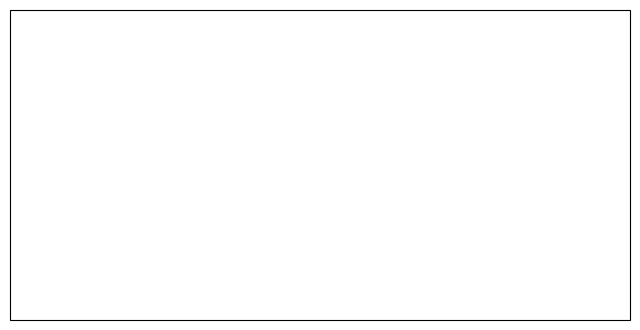

In [6]:
graficar_radar(radar_list[0], campo='DBZH', vmin=-30, vmax=70)

In [4]:
# folder_path = "/opt/backups-operativos/usuarios/anaalabi/nowcasting_radar/data/incoming/2019/01/02_03/"

# radar = pyart.io.read("/home/ana_luz/Tesis/DATOS_RADAR/graficos/RMA1_0303_01_20240107T013034Z.nc")



In [5]:
from .compute import compute_grid_geometry
from .cores import detect_cores_from_colmax
from .filters import GateFilter, GridFilter, create_mask_from_filter
from .geometry import GridGeometry, build_geometry_filename, load_geometry, peek_geometry_metadata, save_geometry


ImportError: attempted relative import with no known parent package

In [ ]:
# .compute 

def compute_grid_geometry(
    gate_x: np.ndarray,
    gate_y: np.ndarray,
    gate_z: np.ndarray,
    grid_shape: Tuple[int, int, int],
    grid_limits: Tuple[Tuple[float, float], ...],
    temp_dir: str,
    radar_altitude: float = 0.0,
    min_radius: float = 250.0,
    h_factor: float = 0.01746,
    nb: float = 1.5,
    bsp: float = 1.2,
    weighting: str = "barnes2",
    max_neighbors: Optional[int] = None,
    toa: float = 17000.0,
    min_beam_h: Optional[np.ndarray] = None,
    blind_range_m: Optional[float] = None,
    n_workers: Optional[int] = None,
    lowest_elev_deg=None,  # Elevación mínima para máscara below-beam
    dtype_val=np.float32,
    dtype_idx=np.int32,
) -> GridGeometry:
    """
    Compute the sparse mapping from grid points to radar gates.

    This function precomputes which radar gates contribute to each grid point
    and with what weight. The result can be saved and reused for fast
    interpolation of any field from the same radar.

    Parameters
    ----------
    gate_x, gate_y, gate_z : np.ndarray
        Flattened gate coordinates in meters, shape (n_gates,)
    grid_shape : tuple
        (nz, ny, nx) grid dimensions
    grid_limits : tuple
        ((z_min, z_max), (y_min, y_max), (x_min, x_max)) in meters
    temp_dir : str
        Directory for temporary files during computation
    radar_altitude : float, optional
        Altitude of radar in meters (default: 0.0)
    min_radius : float, optional
        Minimum radius of influence in meters (default: 250.0)
    beam_factor : float, optional
        ROI = max(min_radius, distance * beam_factor)
        Default: 0.01746 = tan(1°), matching PyART's default
    weighting : str, optional
        Weighting function: 'barnes2' (default), 'cressman', or 'nearest'
    toa : float, optional
        Top of atmosphere - gates above this altitude are excluded
        (default: 17000.0 meters)
    n_workers : int, optional
        Number of parallel workers for computation.
        Default: cpu_count() - 1
        Set to 1 for sequential processing (lower peak memory usage)

    Returns
    -------
    GridGeometry
        Precomputed sparse mapping ready for fast field interpolation

    Notes
    -----
    Memory usage during computation is managed by:
    - Processing one z-level at a time
    - Writing intermediate results to temp files
    - Using multiprocessing to parallelize across levels

    For a typical radar volume with ~3.5M gates and ~900k grid points,
    expect computation time of 2-5 minutes with 4 workers.
    """
    if n_workers is None:
        n_workers = max(1, cpu_count() - 1)

    # Validate inputs
    if not os.path.isdir(temp_dir):
        raise ValueError(f"temp_dir does not exist: {temp_dir}")

    if weighting not in ("barnes2", "cressman", "nearest"):
        raise ValueError(f"Unknown weighting function: {weighting}")

    nz, ny, nx = grid_shape

    # Convert gate_z from absolute altitude to height above radar
    gate_z_relative = gate_z - radar_altitude

    z_coords = np.linspace(grid_limits[0][0], grid_limits[0][1], nz, dtype="float32")
    y_coords = np.linspace(grid_limits[1][0], grid_limits[1][1], ny, dtype="float32")
    x_coords = np.linspace(grid_limits[2][0], grid_limits[2][1], nx, dtype="float32")

    # Preparar grid 2D (Y-X plane)
    yy, xx = np.meshgrid(y_coords, x_coords, indexing="ij")
    grid_y_2d = yy.ravel().astype("float32")
    grid_x_2d = xx.ravel().astype("float32")

    # Precomputar altura mínima del haz para el plano XY (una sola vez)
    # Se pasa a cada worker para saltar voxels debajo del haz más bajo.
    # Se resta medio z_step como margen para no enmascarar niveles que
    # collapse_ppi necesitará interpolar (evita NaN en el nivel z_low).
    if lowest_elev_deg is not None:
        z_step = float(z_coords[1] - z_coords[0]) if len(z_coords) > 1 else 500.0
        below_beam_margin = 0.8 * z_step
        horiz_dist = np.sqrt(grid_x_2d**2 + grid_y_2d**2)
        min_beam_h = (compute_beam_height(horiz_dist, lowest_elev_deg, radar_altitude=0.0) - below_beam_margin).astype(
            "float32"
        )
        logger.info(
            f"  Below-beam mask: elev_min={lowest_elev_deg:.2f}°, margin={below_beam_margin:.0f}m, "
            f"beam_h range=[{min_beam_h.min():.0f}, {min_beam_h.max():.0f}]m"
        )
    else:
        min_beam_h = None

    yy, xx = np.meshgrid(y_coords, x_coords, indexing="ij")
    grid_y_2d = yy.ravel().astype("float64")
    grid_x_2d = xx.ravel().astype("float64")

    # Create mask for gates below toa
    gate_valid_mask = gate_z_relative <= toa
    n_valid_gates = gate_valid_mask.sum()
    n_excluded = gate_z_relative.shape[0] - n_valid_gates

    logger.info(f"Radar altitude: {radar_altitude:.1f} m")
    logger.info(f"Gate Z range (relative to radar): {gate_z_relative.min():.1f} to {gate_z_relative.max():.1f} m")
    logger.info(f"TOA filter: {n_valid_gates:,} gates below {toa}m (above radar), {n_excluded:,} excluded")
    logger.info(f"Processing {nz} z-levels with {n_workers} worker(s)...")

    # Use gate_z_relative for geometry computation
    args_list = [
        (
            iz,
            gz,
            grid_y_2d,
            grid_x_2d,
            gate_x,
            gate_y,
            gate_z_relative,
            gate_valid_mask,
            min_radius,
            h_factor,
            nb,
            bsp,
            weighting,
            max_neighbors,
            temp_dir,
            dtype_val,
            dtype_idx,
            min_beam_h,
            blind_range_m,
        )
        for iz, gz in enumerate(z_coords)
    ]

    if n_workers == 1:
        # Sequential processing
        results = []
        for args in args_list:
            result = _process_single_level(args)
            logger.debug(f"  Level {result[0]}: {result[1]:,} pairs")
            results.append(result)
    else:
        # Parallel processing
        with Pool(n_workers) as pool:
            results = []
            for result in pool.imap_unordered(_process_single_level, args_list):
                logger.debug(f"  Level {result[0]}: {result[1]:,} pairs")
                results.append(result)

    # Sort results by level index
    results.sort(key=lambda x: x[0])

    total_pairs = sum(r[1] for r in results)
    total_grid_points = ny * nx * nz
    logger.info(f"Merging {nz} levels ({total_pairs:,} total pairs)...")

    # Pre-allocate arrays with known sizes - much more memory efficient!
    final_indptr = np.zeros(total_grid_points + 1, dtype="int32")
    final_indices = np.empty(total_pairs, dtype="int32")
    final_weights = np.empty(total_pairs, dtype="float32")

    # Fill pre-allocated arrays level by level
    pair_offset = 0
    point_offset = 0

    for _iz, _n_pairs, temp_file in results:
        # Load level data
        data = np.load(temp_file)
        level_indptr = data["indptr"]
        level_indices = data["gate_indices"]
        level_weights = data["weights"]

        # Number of grid points at this level
        n_level_points = len(level_indptr) - 1

        # Copy indices and weights directly into pre-allocated arrays
        n_level_pairs = len(level_indices)
        if n_level_pairs > 0:
            final_indices[pair_offset : pair_offset + n_level_pairs] = level_indices
            final_weights[pair_offset : pair_offset + n_level_pairs] = level_weights

        # Build indptr for this level with proper offset
        for j in range(n_level_points):
            final_indptr[point_offset + j + 1] = pair_offset + level_indptr[j + 1]

        # Update offsets
        pair_offset += n_level_pairs
        point_offset += n_level_points

        # Explicitly close the npz file and delete references
        data.close()
        del data, level_indptr, level_indices, level_weights

        # Clean up temp file immediately
        os.remove(temp_file)

        # Force garbage collection after each level to keep memory low
        gc.collect()

    logger.info("Merge complete.")

    # Return using pre-allocated arrays directly (no copying needed!)
    return GridGeometry(
        grid_shape=grid_shape,
        grid_limits=grid_limits,
        indptr=final_indptr,
        gate_indices=final_indices,
        weights=final_weights,
        toa=toa,
    )


In [ ]:
# .cores : detect_cores_from_colmax
def detect_cores_from_colmax(
    colmax: np.ndarray,
    x_coords: np.ndarray,
    y_coords: np.ndarray,
    rhohv: Optional[np.ndarray] = None,
    min_dbz: float = config.CORES_MIN_Z,
    min_dbz_updraft: float = config.CORES_MIN_Z_UPDRAFT,
    min_range_m: float = config.CORES_MIN_RANGE,
    dedup_radius_m: float = config.CORES_DEDUP_RADIUS,
    rhohv_threshold: float = config.CORES_RHOHV_THRESHOLD,
    min_pixels: int = config.CORES_MIN_PIXELS,
    min_pixels_updraft: int = config.CORES_MIN_PIXELS_UPDRAFT,
) -> list:
    """
    Detect convective core centroids from a 2D COLMAX reflectivity grid.

    A core is a spatially contiguous region of high reflectivity (≥ ``min_dbz``)
    that passes a minimum-size check, a minimum-range check, and a quality gate
    based on either RhoHV or extreme reflectivity intensity.

    .. note::
        **RhoHV availability**

        This function receives a 2D COLMAX grid which carries no RhoHV
        information per se.  The caller must supply a co-registered 2D
        ``rhohv`` grid of identical shape (e.g. derived from the same
        geometry-mapped volume at the lowest sweep).  When ``rhohv`` is
        ``None``, the meteorological echo gate is skipped entirely and only
        the violent-updraft intensity gate (``max_dbz > min_dbz_updraft``
        with sufficient pixel count) can qualify a blob.  Expect a lower
        recall of weaker convective cells in that mode.

    Parameters
    ----------
    colmax : np.ndarray, shape (NY, NX)
        2D COLMAX reflectivity grid in dBZ.  May be a numpy masked array;
        masked pixels are excluded from all blobs.
    x_coords : np.ndarray, shape (NY, NX)
        Cartesian x coordinates in metres, radar-relative, same grid shape
        as ``colmax``.
    y_coords : np.ndarray, shape (NY, NX)
        Cartesian y coordinates in metres, radar-relative, same grid shape
        as ``colmax``.
    rhohv : np.ndarray (NY, NX) or None, optional
        Co-registered 2D RhoHV grid.  When supplied it enables the
        meteorological echo quality gate. When ``None`` only the updraft
        gate applies (see note above).
    min_dbz : float, optional
        Reflectivity threshold (dBZ) for initial blob detection.
        Defaults to ``config.CORES_MIN_Z`` (52 dBZ).
    min_dbz_updraft : float, optional
        Maximum dBZ required for the violent-updraft quality gate.
        Defaults to ``config.CORES_MIN_Z_UPDRAFT`` (56 dBZ).
    min_range_m : float, optional
        Minimum distance of a blob centroid from the radar origin (metres).
        Blobs with centroids closer than this are rejected as near-range
        artefacts.  Defaults to ``config.CORES_MIN_RANGE`` (12 000 m).
    dedup_radius_m : float, optional
        Merge radius for nearby centroids (metres).  When two cores are within
        this distance of each other, the strongest core's peak-pixel location
        is kept and weaker ones are discarded.  Defaults to
        ``config.CORES_DEDUP_RADIUS`` (8 000 m).
    rhohv_threshold : float, optional
        Minimum mean RhoHV to pass the meteorological echo gate (default
        0.85).
    min_pixels : int, optional
        Minimum blob pixel count for the RhoHV gate path (default 2).
    min_pixels_updraft : int, optional
        Minimum blob pixel count for the updraft gate path (default 5).

    Returns
    -------
    list of dict
        One dict per accepted convective core, sorted by descending
        ``mean_dbz``.  Each dict has the following keys:

        * ``"x_m"`` – centroid x in metres (radar-relative *float*)
        * ``"y_m"`` – centroid y in metres (radar-relative *float*)
        * ``"mean_dbz"`` – mean dBZ of all pixels in the blob (*float*)
        * ``"max_dbz"`` – maximum dBZ in the blob (*float*)
        * ``"pixel_count"`` – number of pixels in the blob (*int*)
        * ``"range_m"`` – distance of centroid from radar origin (*float*)
        * ``"blob_mask"`` – boolean 2D array (same shape as ``colmax``) marking
          all pixels belonging to this core's blob.  When two blobs are merged
          during deduplication their masks are unioned so the footprint covers
          both original blobs.

        Returns an empty list if no cores are detected.

    Notes
    -----
    **Connected-component labelling:**
    :func:`scipy.ndimage.label` on a boolean threshold mask with 4-neighbours
    only (up/down/left/right); diagonal pixels are NOT treated as connected.
    Conservative to avoid merging adjacent but distinct cells.

    **Deduplication strategy:**
    When two accepted cores within ``dedup_radius_m`` are identified, the
    strongest core's peak-pixel location is kept and the weaker cores are
    discarded.  A weighted-mean centroid is intentionally avoided because it
    can fall in a low-dBZ gap between adjacent blobs.

    **Error handling:**
    This function never raises.  Exceptions encountered during processing
    are caught, logged at ``ERROR`` level, and an empty list (or whatever
    was accumulated up to the failure point) is returned.

    Examples
    --------
    >>> import numpy as np
    >>> from radarlib.radar_grid import detect_cores_from_colmax
    >>> ny, nx = 100, 100
    >>> x = np.linspace(-100_000, 100_000, nx)
    >>> y = np.linspace(-100_000, 100_000, ny)
    >>> yy, xx = np.meshgrid(y, x, indexing="ij")
    >>> colmax = np.full((ny, nx), 20.0)
    >>> colmax[50:55, 50:55] = 58.0   # a strong blob
    >>> cores = detect_cores_from_colmax(colmax, xx, yy)
    >>> len(cores)
    1
    """
    accepted: list = []

    try:
        # ------------------------------------------------------------------
        # Step 1 — build threshold mask, excluding masked pixels
        # ------------------------------------------------------------------
        colmax_data = np.ma.getdata(colmax).astype(np.float32, copy=False)
        mask_invalid = np.ma.getmaskarray(colmax)

        valid: np.ndarray = (colmax_data >= min_dbz) & (~mask_invalid)

        # ------------------------------------------------------------------
        # Step 2 — connected-component labelling
        # ------------------------------------------------------------------
        label_array, n_labels = ndimage_label(valid)

        if n_labels == 0:
            logger.debug("detect_cores_from_colmax: no blobs found above threshold %.1f dBZ", min_dbz)
            return []

        logger.debug("detect_cores_from_colmax: %d raw blob(s) found above %.1f dBZ", n_labels, min_dbz)

        # ------------------------------------------------------------------
        # Step 3 — evaluate each blob
        # ------------------------------------------------------------------
        rhohv_data: Optional[np.ndarray] = None
        if rhohv is not None:
            rhohv_data = np.ma.getdata(rhohv).astype(np.float32, copy=False)

        for label_id in range(1, n_labels + 1):
            blob_mask = label_array == label_id
            pixel_count = int(blob_mask.sum())

            # a) minimum blob size (skip single-pixel spikes)
            if pixel_count <= 1:
                continue

            # b) centroid — peak-dBZ pixel (strongest updraft column)
            blob_pixels_dbz = colmax_data[blob_mask]
            peak_idx = int(np.argmax(blob_pixels_dbz))
            x_c = float(x_coords[blob_mask][peak_idx])
            y_c = float(y_coords[blob_mask][peak_idx])

            # c) range from radar origin
            range_m = math.sqrt(x_c * x_c + y_c * y_c)
            if range_m < min_range_m:
                logger.debug(
                    "Blob %d rejected: centroid range %.0f m < min_range %.0f m",
                    label_id,
                    range_m,
                    min_range_m,
                )
                continue

            # d) dBZ statistics
            blob_dbz = colmax_data[blob_mask]
            mean_dbz = float(blob_dbz.mean())
            max_dbz = float(blob_dbz.max())

            # e) quality gate
            rhohv_ok = False
            if rhohv_data is not None and pixel_count > min_pixels:
                mean_rhohv = float(rhohv_data[blob_mask].mean())
                rhohv_ok = mean_rhohv > rhohv_threshold

            updraft_ok = (max_dbz > min_dbz_updraft) and (pixel_count > min_pixels_updraft)

            if not (rhohv_ok or updraft_ok):
                logger.debug(
                    "Blob %d rejected: quality gate failed " "(rhohv_ok=%s, updraft_ok=%s, max_dbz=%.1f, pixels=%d)",
                    label_id,
                    rhohv_ok,
                    updraft_ok,
                    max_dbz,
                    pixel_count,
                )
                continue

            accepted.append(
                {
                    "x_m": x_c,
                    "y_m": y_c,
                    "mean_dbz": mean_dbz,
                    "max_dbz": max_dbz,
                    "pixel_count": pixel_count,
                    "range_m": range_m,
                    "blob_mask": blob_mask,
                }
            )

        # ------------------------------------------------------------------
        # Step 4 — deduplicate by proximity (keep strongest core)
        # ------------------------------------------------------------------
        accepted.sort(key=lambda c: c["mean_dbz"], reverse=True)

        deduplicated: list = []
        merged_flags: set = set()  # Track which candidates have been merged

        for i, candidate in enumerate(accepted):
            if i in merged_flags:
                continue  # Already merged into a previous core

            # Find all candidates close to this one
            close_candidates = [candidate]
            close_indices = [i]

            for j in range(i + 1, len(accepted)):
                if j in merged_flags:
                    continue
                other = accepted[j]
                dx = candidate["x_m"] - other["x_m"]
                dy = candidate["y_m"] - other["y_m"]
                dist = math.sqrt(dx * dx + dy * dy)
                if dist < dedup_radius_m:
                    close_candidates.append(other)
                    close_indices.append(j)

            # If no close candidates, keep this core as-is
            if len(close_candidates) == 1:
                deduplicated.append(candidate)
            else:
                # Keep the strongest core's peak location — do NOT compute a weighted
                # centroid, because the average of two peak pixels may fall in a low-dBZ
                # gap between the blobs and make the dot appear outside the storm.
                merged_core = close_candidates[0].copy()

                # Union blob masks so the footprint covers all merged blobs.
                merged_blob = close_candidates[0]["blob_mask"].copy()
                for other in close_candidates[1:]:
                    merged_blob |= other["blob_mask"]
                merged_core["blob_mask"] = merged_blob
                merged_core["pixel_count"] = int(merged_blob.sum())

                deduplicated.append(merged_core)

                # Mark all merged candidates
                for j in close_indices[1:]:
                    merged_flags.add(j)

                logger.debug(
                    "detect_cores_from_colmax: merged %d core(s) within %.0f m; "
                    "kept strongest centroid: (%.1f, %.1f) m, mean_dbz=%.1f dBZ",
                    len(close_candidates),
                    dedup_radius_m,
                    merged_core["x_m"],
                    merged_core["y_m"],
                    merged_core["mean_dbz"],
                )

        logger.debug(
            "detect_cores_from_colmax: %d core(s) accepted after deduplication " "(%d before)",
            len(deduplicated),
            len(accepted),
        )
        return deduplicated  # already sorted descending by mean_dbz

    except Exception as exc:
        logger.error("detect_cores_from_colmax failed: %s", exc, exc_info=True)
        return accepted  # return whatever was accumulated before the failure


In [ ]:
# .cores_and_tops
"""
cores_and_tops.py — Integration function for convective core and storm top detection.

Provides :func:`generate_cores_and_tops`, the single call-site used inside
:meth:`~radarlib.daemons.product_daemon.ProductGenerationDaemon._generate_raw_cog_products_sync`
to detect convective cores and storm tops from a processed radar volume and write
the results as a GeoJSON FeatureCollection.

This is the **only** module that imports both ``radarlib.radar_grid`` detection
functions and PyART coordinate utilities.  It is imported lazily at the call-site
in ``product_daemon.py`` (local import after the guard block) to keep daemon
startup cost low.

Algorithm Overview
-------------------

1. **Core Detection** (from COLMAX 2D):
   - Connected-component labelling on column-maximum reflectivity grid
   - Quality gates: RhoHV (mean > 0.85) OR violent updraft (max > 56 dBZ)
   - Deduplication: keep strongest core's peak-pixel location
   - Output: List of core dicts with centroid (x_m, y_m) and intensity metrics

2. **Top Detection** (from DBZH 3D, relative to cores):
   - For each detected core, search in cylindrical column (radius from TOPS_DEDUP_RADIUS_M config)
   - Find the **highest altitude with valid DBZH** within that cylinder
   - No thresholds applied: accepts first valid DBZH found at upper levels
   - Output: List of top dicts with altitude and parent core reference

This two-stage design ensures tops are only detected where cores exist, and uses
a simplified (parameterless) algorithm focused on finding tower peaks.

GeoJSON schema reference
------------------------
::

    {
      "type": "FeatureCollection",
      "features": [
        {
          "type": "Feature",
          "geometry": {"type": "Point", "coordinates": [lon, lat]},
          "properties": {
            "type": "core",
            "intensity_dbz": 54,
            "radar_code": "RMA1",
            "observation_time": "2026-04-28T15:10:00Z"
          }
        },
        {
          "type": "Feature",
          "geometry": {"type": "Point", "coordinates": [lon, lat]},
          "properties": {
            "type": "top",
            "altitude_m": 12500,
            "dbz": 25.5,
            "parent_core_dbz": 54,
            "radar_code": "RMA1",
            "observation_time": "2026-04-28T15:10:00Z"
          }
        }
      ]
    }

Output file path
----------------
``{output_dir}/YYYY/MM/DD/{radar_code}_{strategy}_{vol_nr}_{timestamp}_TOPS_CORES.geojson``

where ``{timestamp}`` follows the same ``%Y%m%dT%H%M%SZ`` format used for COG
filenames throughout this codebase.

The caller is responsible for passing a **ceiled** ``observation_time``
(``floor(obs_time + 10 min, 10 min)``) so that the GeoJSON timestamp aligns
with the corresponding COG products.  When the ceiled and rounded timestamps
differ, the caller also writes a second copy of the file using the rounded
timestamp — the same dual-write pattern used for COGs.  This module always
writes exactly one file at whatever ``observation_time`` it receives.

When this function returns ``None`` (no detections) and the ceiled and rounded
timestamps differ, the caller must also **delete** any pre-existing
rounded-timestamp GeoJSON from an earlier scan that landed in the same bucket,
because the COG rounded copy has already been overwritten unconditionally.
Failing to do this leaves a stale tops/cores file paired with a newer COG that
contains no convective cells — the adjacent-frame mismatch visible in the
frontend.
"""

from __future__ import annotations

import json
import logging
import time
from datetime import datetime
from pathlib import Path
from typing import Optional

import numpy as np

logger = logging.getLogger(__name__)


def generate_cores_and_tops(
    colmax_2d: np.ndarray,
    dbzh_3d: np.ndarray,
    x_coords: np.ndarray,
    y_coords: np.ndarray,
    z_coords: np.ndarray,
    radar_lat: float,
    radar_lon: float,
    observation_time: datetime,
    radar_code: str,
    strategy: str,
    vol_nr: str,
    output_dir: Path,
    rhohv_3d: Optional[np.ndarray] = None,
    rhohv_2d: Optional[np.ndarray] = None,
) -> Optional[Path]:
    """
    Detect convective cores and storm tops and write one GeoJSON file per volume.

    This function wraps the core implementation with an outermost ``try/except``
    so that **any** unexpected failure is logged but never re-raised.  The calling
    product-generation pipeline must not be aborted by this secondary product.

    Parameters
    ----------
    colmax_2d : np.ndarray, shape (NY, NX)
        2D column-maximum reflectivity grid in dBZ.
    dbzh_3d : np.ndarray, shape (NZ, NY, NX)
        3D Cartesian reflectivity grid in dBZ produced by ``apply_geometry``.
    x_coords : np.ndarray, shape (NY, NX)
        Cartesian x coordinates in metres, radar-relative.
    y_coords : np.ndarray, shape (NY, NX)
        Cartesian y coordinates in metres, radar-relative.
    z_coords : np.ndarray, shape (NZ,)
        1D array of altitude values in metres (from ``geometry.z_levels()``).
    radar_lat : float
        Radar latitude in decimal degrees.
    radar_lon : float
        Radar longitude in decimal degrees.
    observation_time : datetime
        Timezone-aware UTC datetime of the observation.
    radar_code : str
        Radar station identifier (e.g. ``"RMA1"``).
    strategy : str
        Volume strategy code (e.g. ``"0315"``).
    vol_nr : str
        Volume number string (e.g. ``"01"``).
    output_dir : Path
        Root directory for GeoJSON output.  Subdirectories are created
        automatically following the pattern
        ``{output_dir}/YYYY/MM/DD/``.
    rhohv_3d : np.ndarray (NZ, NY, NX) or None, optional
        Co-registered 3D cross-correlation ratio grid for quality gating.
        Pass ``None`` when the RhoHV field is absent from the volume; detection
        will run with the quality gate disabled.
    rhohv_2d : np.ndarray (NY, NX) or None, optional
        2D RhoHV grid, used for core detection and quality gating.

    Returns
    -------
    Path or None
        Absolute path of the written GeoJSON file, or ``None`` when:

        * both ``cores`` and ``tops`` detection results are empty, **or**
        * the output directory cannot be created, **or**
        * writing the GeoJSON file fails, **or**
        * any unexpected exception is raised.
    """
    t0 = time.monotonic()
    try:
        return _run(
            colmax_2d=colmax_2d,
            dbzh_3d=dbzh_3d,
            x_coords=x_coords,
            y_coords=y_coords,
            z_coords=z_coords,
            radar_lat=radar_lat,
            radar_lon=radar_lon,
            observation_time=observation_time,
            radar_code=radar_code,
            strategy=strategy,
            vol_nr=vol_nr,
            output_dir=output_dir,
            rhohv_3d=rhohv_3d,
            rhohv_2d=rhohv_2d,
            t0=t0,
        )
    except Exception as exc:
        elapsed_ms = int((time.monotonic() - t0) * 1000)
        logger.error(
            "CORES_TOPS radar=%s time=%s elapsed=%dms unexpected error: %s",
            radar_code,
            observation_time.strftime("%Y-%m-%dT%H:%M:%SZ"),
            elapsed_ms,
            exc,
            exc_info=True,
        )
        return None


# ---------------------------------------------------------------------------
# Internal implementation
# ---------------------------------------------------------------------------


def _run(
    colmax_2d: np.ndarray,
    dbzh_3d: np.ndarray,
    x_coords: np.ndarray,
    y_coords: np.ndarray,
    z_coords: np.ndarray,
    radar_lat: float,
    radar_lon: float,
    observation_time: datetime,
    radar_code: str,
    strategy: str,
    vol_nr: str,
    output_dir: Path,
    rhohv_3d: Optional[np.ndarray],
    rhohv_2d: Optional[np.ndarray],
    t0: float,
) -> Optional[Path]:
    """Internal worker — called exclusively from :func:`generate_cores_and_tops`."""
    # Lazy imports: only pulled in when actually called, keeping daemon startup fast.
    import pyproj
    from scipy.spatial import ConvexHull

    from radarlib.radar_grid import detect_cores_from_colmax, detect_tops_from_cores

    obs_time_str = observation_time.strftime("%Y-%m-%dT%H:%M:%SZ")

    # ------------------------------------------------------------------
    # Compute the COG affine transform (EPSG:3857) using exactly the same
    # algorithm as _compute_crs_bounds in geotiff.py, so that each dot's
    # lon/lat resolves to the geographic CENTER of its corresponding COG
    # pixel rather than to the AEQD cell's theoretical geographic position.
    # The two differ by up to 3–4 km at long range (non-linear AEQD→EPSG:3857
    # distortion inside an affine approximation), which is enough to place a
    # dot several pixels away from the high-dBZ pixel it represents.
    # ------------------------------------------------------------------
    ny, nx = x_coords.shape
    x_min = float(x_coords[0, 0])
    x_max = float(x_coords[0, -1])
    y_min = float(y_coords[0, 0])
    y_max = float(y_coords[-1, 0])
    dx_aeqd = (x_max - x_min) / (nx - 1) if nx > 1 else 1.0
    dy_aeqd = (y_max - y_min) / (ny - 1) if ny > 1 else 1.0

    _local_proj = pyproj.Proj(proj="aeqd", lat_0=radar_lat, lon_0=radar_lon, x_0=0, y_0=0, datum="WGS84")
    _to_wgs84 = pyproj.Transformer.from_proj(_local_proj, pyproj.CRS("EPSG:4326"), always_xy=True)
    _corner_lons, _corner_lats = [], []
    for _x in [x_min, x_max]:
        for _y in [y_min, y_max]:
            _lon, _lat = _to_wgs84.transform(_x, _y)
            _corner_lons.append(_lon)
            _corner_lats.append(_lat)
    _west, _east = min(_corner_lons), max(_corner_lons)
    _south, _north = min(_corner_lats), max(_corner_lats)

    _to_3857 = pyproj.Transformer.from_crs("EPSG:4326", "EPSG:3857", always_xy=True)
    _from_3857 = pyproj.Transformer.from_crs("EPSG:3857", "EPSG:4326", always_xy=True)
    _merc_pts = [_to_3857.transform(_lon, _lat) for _lon in [_west, _east] for _lat in [_south, _north]]
    _west_m = min(p[0] for p in _merc_pts)
    _east_m = max(p[0] for p in _merc_pts)
    _south_m = min(p[1] for p in _merc_pts)
    _north_m = max(p[1] for p in _merc_pts)
    _dx_m = (_east_m - _west_m) / nx
    _dy_m = (_north_m - _south_m) / ny

    def _cog_pixel_lonlat(aeqd_x: float, aeqd_y: float) -> tuple:
        """Return (lon, lat) of the geographic centre of the COG pixel for (aeqd_x, aeqd_y)."""
        col = int(round((aeqd_x - x_min) / dx_aeqd))
        row = int(round((aeqd_y - y_min) / dy_aeqd))
        col = max(0, min(nx - 1, col))
        row = max(0, min(ny - 1, row))
        cog_col = col
        cog_row = (ny - 1) - row  # flipud: row 0 of COG = northernmost AEQD row
        px_merc_x = _west_m + (cog_col + 0.5) * _dx_m
        px_merc_y = _north_m - (cog_row + 0.5) * _dy_m
        return _from_3857.transform(px_merc_x, px_merc_y)

    def _blob_to_polygon(blob_mask: np.ndarray):
        """Convert a boolean blob mask to a closed GeoJSON coordinate ring via convex hull.

        Returns a list of [lon, lat] pairs (ring closed: first == last), or None
        when the blob is too small to form a valid convex hull.
        """
        rows, cols = np.where(blob_mask)
        if len(rows) < 3:
            return None

        grid_cols = np.round((x_coords[rows, cols] - x_min) / dx_aeqd).astype(int)
        grid_rows = np.round((y_coords[rows, cols] - y_min) / dy_aeqd).astype(int)
        np.clip(grid_cols, 0, nx - 1, out=grid_cols)
        np.clip(grid_rows, 0, ny - 1, out=grid_rows)

        cog_rows_arr = (ny - 1) - grid_rows
        merc_xs = _west_m + (grid_cols + 0.5) * _dx_m
        merc_ys = _north_m - (cog_rows_arr + 0.5) * _dy_m

        lons, lats = _from_3857.transform(merc_xs, merc_ys)
        unique_pts = np.unique(np.column_stack([lons, lats]), axis=0)

        if len(unique_pts) < 3:
            return None

        try:
            hull = ConvexHull(unique_pts)
            ring = [[float(unique_pts[v, 0]), float(unique_pts[v, 1])] for v in hull.vertices]
            ring.append(ring[0])
            return ring
        except Exception:
            return None

    # ------------------------------------------------------------------
    # Convective core detection
    # ------------------------------------------------------------------
    cores: list = []
    try:
        cores = detect_cores_from_colmax(
            colmax=colmax_2d,
            x_coords=x_coords,
            y_coords=y_coords,
            rhohv=rhohv_2d,
        )
    except Exception as exc:
        logger.warning(
            "CORES_TOPS radar=%s: core detection raised %s: %s — " "skipping cores, and thus no tops will be detected.",
            radar_code,
            type(exc).__name__,
            exc,
        )

    # ------------------------------------------------------------------
    # Storm top detection (only if cores were found)
    # ------------------------------------------------------------------
    tops: list = []
    if cores:
        try:
            tops = detect_tops_from_cores(
                cores=cores,
                grid_3d=dbzh_3d,
                x_coords=x_coords,
                y_coords=y_coords,
                z_coords=z_coords,
            )
        except Exception as exc:
            logger.warning(
                "CORES_TOPS radar=%s: tops detection raised %s: %s",
                radar_code,
                type(exc).__name__,
                exc,
            )
    else:
        logger.debug(
            "CORES_TOPS radar=%s time=%s: no cores detected — skipping tops detection.",
            radar_code,
            obs_time_str,
        )

    # ------------------------------------------------------------------
    # Nothing detected — skip file write
    # ------------------------------------------------------------------
    if not cores and not tops:
        logger.debug(
            "CORES_TOPS radar=%s time=%s: no features detected — GeoJSON not written.",
            radar_code,
            obs_time_str,
        )
        return None

    # ------------------------------------------------------------------
    # Build GeoJSON features.
    # Each dot is placed at the geographic centre of its corresponding COG
    # pixel (using the inverse of the same affine transform the COG was
    # created with), so the dot always lands exactly on that pixel in the
    # frontend display.
    # ------------------------------------------------------------------
    features: list = []

    for core in cores:
        lon, lat = _cog_pixel_lonlat(core["x_m"], core["y_m"])
        features.append(
            {
                "type": "Feature",
                "geometry": {
                    "type": "Point",
                    "coordinates": [float(lon), float(lat)],
                },
                "properties": {
                    "type": "core",
                    "intensity_dbz": int(core["mean_dbz"]),
                    "radar_code": radar_code,
                    "observation_time": obs_time_str,
                },
            }
        )

        # Blob footprint polygon (convex hull of the core's pixel cluster)
        blob_mask = core.get("blob_mask")
        if blob_mask is not None:
            ring = _blob_to_polygon(blob_mask)
            if ring is not None:
                features.append(
                    {
                        "type": "Feature",
                        "geometry": {
                            "type": "Polygon",
                            "coordinates": [ring],
                        },
                        "properties": {
                            "type": "blob",
                            "intensity_dbz": int(core["mean_dbz"]),
                            "max_dbz": int(core["max_dbz"]),
                            "pixel_count": int(core["pixel_count"]),
                            "radar_code": radar_code,
                            "observation_time": obs_time_str,
                        },
                    }
                )

    for top in tops:
        lon, lat = _cog_pixel_lonlat(top["x_m"], top["y_m"])
        features.append(
            {
                "type": "Feature",
                "geometry": {
                    "type": "Point",
                    "coordinates": [float(lon), float(lat)],
                },
                "properties": {
                    "type": "top",
                    "altitude_m": int(top["altitude_m"]),
                    "dbz": float(top["dbz"]),
                    "radar_code": radar_code,
                    "observation_time": obs_time_str,
                    "parent_core_dbz": int(top["core_mean_dbz"]),
                },
            }
        )

    geojson: dict = {"type": "FeatureCollection", "features": features}

    # ------------------------------------------------------------------
    # Build output path:
    # {output_dir}/YYYY/MM/DD/
    # {radar_code}_{strategy}_{vol_nr}_{timestamp}_TOPS_CORES.geojson
    # The timestamp format matches the COG filename convention: %Y%m%dT%H%M%SZ
    # ------------------------------------------------------------------
    timestamp_str = observation_time.strftime("%Y%m%dT%H%M%SZ")
    subdir = (
        Path(output_dir)
        / f"{observation_time.year:04d}"
        / f"{observation_time.month:02d}"
        / f"{observation_time.day:02d}"
    )
    filename = f"{radar_code}_{strategy}_{vol_nr}_{timestamp_str}_TOPS_CORES.geojson"
    output_path = subdir / filename

    # ------------------------------------------------------------------
    # Create output directory
    # ------------------------------------------------------------------
    try:
        subdir.mkdir(parents=True, exist_ok=True)
    except Exception as exc:
        logger.error(
            "CORES_TOPS radar=%s: cannot create output directory %s: %s",
            radar_code,
            subdir,
            exc,
        )
        return None

    # ------------------------------------------------------------------
    # Write GeoJSON — compact encoding, no trailing newline
    # ------------------------------------------------------------------
    try:
        with open(output_path, "w", encoding="utf-8") as fh:
            json.dump(geojson, fh, separators=(",", ":"))
    except Exception as exc:
        logger.error(
            "CORES_TOPS radar=%s: failed to write GeoJSON %s: %s",
            radar_code,
            output_path,
            exc,
            exc_info=True,
        )
        return None

    elapsed_ms = int((time.monotonic() - t0) * 1000)
    logger.info(
        "CORES_TOPS radar=%s time=%s cores=%d tops=%d elapsed=%dms -> %s",
        radar_code,
        obs_time_str,
        len(cores),
        len(tops),
        elapsed_ms,
        output_path.name,
    )
    return output_path


In [ ]:
# .filters

"""
Gate filters for excluding radar gates from interpolation.

Similar to PyART's GateFilter but designed to work with our interpolation pipeline.
"""

import logging
from typing import Callable, List, Optional, Tuple

import numpy as np

logger = logging.getLogger(__name__)


class GateFilter:
    """
    A class for filtering radar gates based on various criteria.

    The filter maintains a boolean mask where True = excluded gate.
    Multiple filter conditions can be combined (OR logic - if any
    condition excludes a gate, it's excluded).

    Parameters
    ----------
    radar : pyart.core.Radar
        PyART radar object

    Examples
    --------
    >>> gf = GateFilter(radar)
    >>> gf.exclude_below('DBZH', -10)      # Exclude low reflectivity
    >>> gf.exclude_below('RHOHV', 0.7)     # Exclude low correlation
    >>> gf.exclude_above('ZDR', 8)         # Exclude high ZDR
    >>> gf.exclude_invalid('DBZH')         # Exclude NaN/Inf in DBZH
    >>>
    >>> # Use the filter
    >>> filter_mask = gf.gate_excluded
    >>> data, field_mask = get_field_data(radar, 'DBZH')
    >>> combined_mask = field_mask | filter_mask
    >>> grid = apply_geometry(geometry, data, combined_mask)
    """

    def __init__(self, radar):
        """
        Initialize with all gates included (none excluded).

        Parameters
        ----------
        radar : pyart.core.Radar
            PyART radar object
        """
        self.radar = radar
        self.n_gates = radar.nrays * radar.ngates
        self._gate_excluded = np.zeros(self.n_gates, dtype=bool)
        self._filter_history: List[str] = []

    @property
    def gate_excluded(self) -> np.ndarray:
        """Boolean mask where True = gate is excluded."""
        return self._gate_excluded

    @property
    def gate_included(self) -> np.ndarray:
        """Boolean mask where True = gate is included."""
        return ~self._gate_excluded

    def n_excluded(self) -> int:
        """Return number of excluded gates."""
        return self._gate_excluded.sum()

    def n_included(self) -> int:
        """Return number of included gates."""
        return (~self._gate_excluded).sum()

    def summary(self) -> str:
        """Return a summary of the filter."""
        lines = [
            "GateFilter Summary:",
            f"  Total gates: {self.n_gates:,}",
            f"  Excluded: {self.n_excluded():,} ({100*self.n_excluded()/self.n_gates:.1f}%)",
            f"  Included: {self.n_included():,} ({100*self.n_included()/self.n_gates:.1f}%)",
            f"  Filters applied ({len(self._filter_history)}):",
        ]
        for f in self._filter_history:
            lines.append(f"    - {f}")
        return "\n".join(lines)

    def __repr__(self) -> str:
        return f"GateFilter(excluded={self.n_excluded():,}/{self.n_gates:,}, filters={len(self._filter_history)})"

    # def _get_field_data(self, field_name: str) -> np.ndarray:
    #     """Get flattened field data."""
    #     return np.ma.getdata(self.radar.fields[field_name]['data']).ravel().astype('float32')
    def _get_field_data(self, field_name: str) -> np.ndarray:
        """
        Get flattened field data.

        Note: This returns raw data values. Invalid values (NaN, Inf) are
        still present. Use _get_valid_field_data() when you need to know
        which values are valid.
        """
        field = self.radar.fields[field_name]["data"]
        # Apply masked_invalid to properly handle NaN/Inf even if mask is scalar False
        field_masked = np.ma.masked_invalid(field)
        return np.ma.getdata(field_masked).ravel().astype("float32")

    def _add_filter(self, mask: np.ndarray, description: str) -> "GateFilter":
        """Add a filter mask and record it."""
        self._gate_excluded = self._gate_excluded | mask
        self._filter_history.append(description)
        return self

    # -------------------------------------------------------------------------
    # Basic threshold filters
    # -------------------------------------------------------------------------

    def exclude_below(self, field_name: str, threshold: float) -> "GateFilter":
        """
        Exclude gates where field value is below threshold.

        Parameters
        ----------
        field_name : str
            Name of the field to filter on
        threshold : float
            Gates with values < threshold are excluded

        Returns
        -------
        self : GateFilter
            Returns self for method chaining
        """
        if field_name not in self.radar.fields:
            logger.warning(f"Field '{field_name}' not found in radar. No gates excluded.")
            return self
        data = self._get_field_data(field_name)
        mask = data < threshold
        return self._add_filter(mask, f"{field_name} < {threshold}")

    def exclude_above(self, field_name: str, threshold: float) -> "GateFilter":
        """
        Exclude gates where field value is above threshold.

        Parameters
        ----------
        field_name : str
            Name of the field to filter on
        threshold : float
            Gates with values > threshold are excluded

        Returns
        -------
        self : GateFilter
            Returns self for method chaining
        """
        if field_name not in self.radar.fields:
            logger.warning(f"Field '{field_name}' not found in radar. No gates excluded.")
            return self
        data = self._get_field_data(field_name)
        mask = data > threshold
        return self._add_filter(mask, f"{field_name} > {threshold}")

    def exclude_between(self, field_name: str, low: float, high: float) -> "GateFilter":
        """
        Exclude gates where field value is between low and high.

        Parameters
        ----------
        field_name : str
            Name of the field to filter on
        low : float
            Lower bound (exclusive)
        high : float
            Upper bound (exclusive)

        Returns
        -------
        self : GateFilter
            Returns self for method chaining
        """
        if field_name not in self.radar.fields:
            logger.warning(f"Field '{field_name}' not found in radar. No gates excluded.")
            return self
        data = self._get_field_data(field_name)
        mask = (data > low) & (data < high)
        return self._add_filter(mask, f"{low} < {field_name} < {high}")

    def exclude_outside(self, field_name: str, low: float, high: float) -> "GateFilter":
        """
        Exclude gates where field value is outside [low, high] range.

        Parameters
        ----------
        field_name : str
            Name of the field to filter on
        low : float
            Lower bound
        high : float
            Upper bound

        Returns
        -------
        self : GateFilter
            Returns self for method chaining
        """
        if field_name not in self.radar.fields:
            logger.warning(f"Field '{field_name}' not found in radar. No gates excluded.")
            return self
        data = self._get_field_data(field_name)
        mask = (data < low) | (data > high)
        return self._add_filter(mask, f"{field_name} outside [{low}, {high}]")

    def exclude_equal(self, field_name: str, value: float, atol: float = 1e-5) -> "GateFilter":
        """
        Exclude gates where field value equals a specific value.

        Parameters
        ----------
        field_name : str
            Name of the field to filter on
        value : float
            Value to exclude
        atol : float
            Absolute tolerance for comparison

        Returns
        -------
        self : GateFilter
            Returns self for method chaining
        """
        if field_name not in self.radar.fields:
            logger.warning(f"Field '{field_name}' not found in radar. No gates excluded.")
            return self
        data = self._get_field_data(field_name)
        mask = np.abs(data - value) < atol
        return self._add_filter(mask, f"{field_name} == {value}")

    # -------------------------------------------------------------------------
    # Invalid data filters
    # -------------------------------------------------------------------------

    def exclude_invalid(self, field_name: str) -> "GateFilter":
        """
        Exclude gates with invalid data (NaN, Inf) in the specified field.

        Parameters
        ----------
        field_name : str
            Name of the field to check

        Returns
        -------
        self : GateFilter
            Returns self for method chaining
        """
        if field_name not in self.radar.fields:
            logger.warning(f"Field '{field_name}' not found in radar. No gates excluded.")
            return self
        data = self._get_field_data(field_name)
        mask = np.isnan(data) | np.isinf(data)
        return self._add_filter(mask, f"{field_name} invalid (NaN/Inf)")

    def exclude_masked(self, field_name: str) -> "GateFilter":
        """
        Exclude gates that are masked in the original radar field.

        Parameters
        ----------
        field_name : str
            Name of the field to check

        Returns
        -------
        self : GateFilter
            Returns self for method chaining
        """
        if field_name not in self.radar.fields:
            logger.warning(f"Field '{field_name}' not found in radar. No gates excluded.")
            return self
        field = self.radar.fields[field_name]["data"]
        if isinstance(field, np.ma.MaskedArray):
            mask = np.ma.getmaskarray(field).ravel()
        else:
            mask = np.zeros(self.n_gates, dtype=bool)
        return self._add_filter(mask, f"{field_name} masked")

    def exclude_all_invalid(self, field_name: str) -> "GateFilter":
        """
        Exclude gates with any invalid data: NaN, Inf, or masked.

        This is equivalent to calling exclude_invalid() and exclude_masked().

        Parameters
        ----------
        field_name : str
            Name of the field to check

        Returns
        -------
        self : GateFilter
            Returns self for method chaining
        """
        if field_name not in self.radar.fields:
            logger.warning(f"Field '{field_name}' not found in radar. No gates excluded.")
            return self
        field = self.radar.fields[field_name]["data"]
        field_masked = np.ma.masked_invalid(field)
        mask = np.ma.getmaskarray(field_masked).ravel()
        return self._add_filter(mask, f"{field_name} all invalid (NaN/Inf/masked)")

    # -------------------------------------------------------------------------
    # Geometry-based filters
    # -------------------------------------------------------------------------

    def exclude_below_altitude(self, altitude: float) -> "GateFilter":
        """
        Exclude gates below a certain altitude.

        Parameters
        ----------
        altitude : float
            Altitude threshold in meters

        Returns
        -------
        self : GateFilter
            Returns self for method chaining
        """
        gate_alt = self.radar.gate_altitude["data"].ravel()
        mask = gate_alt < altitude
        return self._add_filter(mask, f"altitude < {altitude}m")

    def exclude_above_altitude(self, altitude: float) -> "GateFilter":
        """
        Exclude gates above a certain altitude.

        Parameters
        ----------
        altitude : float
            Altitude threshold in meters

        Returns
        -------
        self : GateFilter
            Returns self for method chaining
        """
        gate_alt = self.radar.gate_altitude["data"].ravel()
        mask = gate_alt > altitude
        return self._add_filter(mask, f"altitude > {altitude}m")

    def exclude_below_range(self, range_min: float) -> "GateFilter":
        """
        Exclude gates closer than a certain range from radar.

        Parameters
        ----------
        range_min : float
            Minimum range in meters

        Returns
        -------
        self : GateFilter
            Returns self for method chaining
        """
        # Range is 1D, need to broadcast to all rays
        ranges = self.radar.range["data"]
        range_2d = np.broadcast_to(ranges, (self.radar.nrays, self.radar.ngates))
        mask = range_2d.ravel() < range_min
        return self._add_filter(mask, f"range < {range_min}m")

    def exclude_above_range(self, range_max: float) -> "GateFilter":
        """
        Exclude gates farther than a certain range from radar.

        Parameters
        ----------
        range_max : float
            Maximum range in meters

        Returns
        -------
        self : GateFilter
            Returns self for method chaining
        """
        ranges = self.radar.range["data"]
        range_2d = np.broadcast_to(ranges, (self.radar.nrays, self.radar.ngates))
        mask = range_2d.ravel() > range_max
        return self._add_filter(mask, f"range > {range_max}m")

    def exclude_below_elevation_angle(self, min_elev: float) -> "GateFilter":
        """
        Exclude gates with elevation angle below a threshold.

        Parameters
        ----------
        min_elev : float
            Minimum elevation angle in degrees

        Returns
        -------
        self : GateFilter
            Returns self for method chaining

        Notes
        -----
        Elevation angles are per-ray, so all gates in a ray with elevation
        below the threshold will be excluded. Useful for filtering out
        low-elevation scans that may have ground clutter or be affected by terrain.

        Example
        -------
        >>> gf.exclude_below_elevation_angle(2.0)  # Exclude angles < 2 degrees
        """
        elev_angles = self.radar.elevation["data"]  # shape (nrays,)
        # shape (nrays * ngates,)
        elev_repeated = np.repeat(elev_angles, self.radar.ngates)
        mask = elev_repeated < min_elev
        return self._add_filter(mask, f"elevation angle < {min_elev}°")

    def exclude_above_elevation_angle(self, max_elev: float) -> "GateFilter":
        """
        Exclude gates with elevation angle above a threshold.

        Parameters
        ----------
        max_elev : float
            Maximum elevation angle in degrees

        Returns
        -------
        self : GateFilter
            Returns self for method chaining

        Notes
        -----
        Elevation angles are per-ray, so all gates in a ray with elevation
        above the threshold will be excluded. Useful for filtering out very
        high elevation angles where the beam is nearly vertical and gate
        volumes become very large or sampling becomes sparse.

        Example
        -------
        >>> gf.exclude_above_elevation_angle(30.0)  # Exclude angles > 30 degrees
        """
        elev_angles = self.radar.elevation["data"]  # shape (nrays,)
        # shape (nrays * ngates,)
        elev_repeated = np.repeat(elev_angles, self.radar.ngates)
        mask = elev_repeated > max_elev
        return self._add_filter(mask, f"elevation angle > {max_elev}°")

    def exclude_outside_elevation_range(self, min_elev: float, max_elev: float) -> "GateFilter":
        """
        Exclude gates with elevation angle outside [min_elev, max_elev] range.

        Parameters
        ----------
        min_elev : float
            Minimum elevation angle in degrees (inclusive)
        max_elev : float
            Maximum elevation angle in degrees (inclusive)

        Returns
        -------
        self : GateFilter
            Returns self for method chaining

        Example
        -------
        >>> gf.exclude_outside_elevation_range(1.0, 25.0)
        """
        elev_angles = self.radar.elevation["data"]  # shape (nrays,)
        # shape (nrays * ngates,)
        elev_repeated = np.repeat(elev_angles, self.radar.ngates)
        mask = (elev_repeated < min_elev) | (elev_repeated > max_elev)
        return self._add_filter(mask, f"elevation angle outside [{min_elev}°, {max_elev}°]")

    # -------------------------------------------------------------------------
    # Custom filters
    # -------------------------------------------------------------------------

    def exclude_where(self, mask: np.ndarray, description: str = "custom") -> "GateFilter":
        """
        Exclude gates based on a custom boolean mask.

        Parameters
        ----------
        mask : np.ndarray
            Boolean array of shape (nrays, ngates) or (nrays * ngates,)
            where True = exclude
        description : str
            Description of this filter for the summary

        Returns
        -------
        self : GateFilter
            Returns self for method chaining
        """
        mask_flat = mask.ravel().astype(bool)
        if len(mask_flat) != self.n_gates:
            raise ValueError(f"Mask size {len(mask_flat)} doesn't match n_gates {self.n_gates}")
        return self._add_filter(mask_flat, description)

    def exclude_by_function(
        self, field_name: str, func: Callable[[np.ndarray], np.ndarray], description: str = "custom function"
    ) -> "GateFilter":
        """
        Exclude gates based on a custom function applied to field data.

        Parameters
        ----------
        field_name : str
            Name of the field to process
        func : callable
            Function that takes field data array and returns boolean mask
            where True = exclude
        description : str
            Description of this filter

        Returns
        -------
        self : GateFilter
            Returns self for method chaining

        Example
        -------
        >>> # Exclude gates where DBZH is in the bottom 10%
        >>> gf.exclude_by_function('DBZH',
        ...     lambda x: x < np.nanpercentile(x, 10),
        ...     description="DBZH bottom 10%")
        """
        data = self._get_field_data(field_name)
        mask = func(data)
        return self._add_filter(mask, f"{field_name}: {description}")

    # -------------------------------------------------------------------------
    # Utility methods
    # -------------------------------------------------------------------------

    def copy(self) -> "GateFilter":
        """Create a copy of this filter."""
        new_filter = GateFilter(self.radar)
        new_filter._gate_excluded = self._gate_excluded.copy()
        new_filter._filter_history = self._filter_history.copy()
        return new_filter

    def reset(self) -> "GateFilter":
        """Reset the filter to include all gates."""
        self._gate_excluded = np.zeros(self.n_gates, dtype=bool)
        self._filter_history = []
        return self

    def include_all(self) -> "GateFilter":
        """Alias for reset()."""
        return self.reset()

    def exclude_all(self) -> "GateFilter":
        """Exclude all gates."""
        self._gate_excluded = np.ones(self.n_gates, dtype=bool)
        self._filter_history.append("exclude all")
        return self


def create_mask_from_filter(
    radar, field_name: str, gatefilter: Optional[GateFilter] = None
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Create field data and combined mask from radar field and optional filter.

    This is a convenience function that combines get_field_data behavior
    with gate filtering.

    Parameters
    ----------
    radar : pyart.core.Radar
        PyART radar object
    field_name : str
        Name of the field to extract
    gatefilter : GateFilter, optional
        Gate filter to apply. If None, only invalid data is masked.

    Returns
    -------
    field_data : np.ndarray
        Flattened field values
    combined_mask : np.ndarray
        Combined mask (True = excluded) from invalid data and filter
    """
    field = radar.fields[field_name]["data"]
    field_masked = np.ma.masked_invalid(field)

    field_data = np.ma.getdata(field_masked).ravel().astype("float32")
    field_mask = np.ma.getmaskarray(field_masked).ravel()

    if gatefilter is not None:
        combined_mask = field_mask | gatefilter.gate_excluded
    else:
        combined_mask = field_mask

    return field_data, combined_mask


# ============================================================================
# Grid Filters - Applied after interpolation on 2D projections
# ============================================================================

# ============================================================================
# Grid Filters - Applied after interpolation on 2D projections
# ============================================================================


class GridFilter:
    """
    A simple class for filtering 2D grid values after interpolation.

    This filter works directly on grid arrays, setting values to NaN based
    on simple threshold criteria.

    Examples
    --------
    >>> # Create a colmax 2D projection
    >>> colmax = column_max(grid)  # shape (ny, nx)
    >>>
    >>> # Create a filter and apply it
    >>> gf = GridFilter()
    >>> filtered = gf.apply_below(colmax, 15)  # Set values < 15 to NaN
    >>>
    >>> # Or chain multiple filters
    >>> filtered = colmax.copy()
    >>> filtered = GridFilter().apply_below(filtered, 15)
    >>> filtered = GridFilter().apply_above(filtered, 45)
    """

    def apply_below(self, grid: np.ndarray, threshold: float, fill_value: float = np.nan) -> np.ndarray:
        """
        Set grid values below threshold to fill_value (NaN by default).

        Parameters
        ----------
        grid : np.ndarray
            2D grid array
        threshold : float
            Values below this are set to fill_value
        fill_value : float, optional
            Value to use for filtered points (default: np.nan)

        Returns
        -------
        np.ndarray
            Filtered grid (original is not modified)

        Example
        -------
        >>> colmax = np.array([[10, 20, 30], [15, 25, 35]])
        >>> gf = GridFilter()
        >>> result = gf.apply_below(colmax, 15)
        >>> # result[0, 0] = nan, result[0, 1] = 20, etc.
        """
        result = grid.copy()
        result[result < threshold] = fill_value
        return result

    def apply_above(self, grid: np.ndarray, threshold: float, fill_value: float = np.nan) -> np.ndarray:
        """
        Set grid values above threshold to fill_value (NaN by default).

        Parameters
        ----------
        grid : np.ndarray
            2D grid array
        threshold : float
            Values above this are set to fill_value
        fill_value : float, optional
            Value to use for filtered points (default: np.nan)

        Returns
        -------
        np.ndarray
            Filtered grid (original is not modified)

        Example
        -------
        >>> colmax = np.array([[10, 20, 30], [15, 25, 45]])
        >>> gf = GridFilter()
        >>> result = gf.apply_above(colmax, 45)
        >>> # result[0, 2] = 30, result[1, 2] = nan, etc.
        """
        result = grid.copy()
        result[result > threshold] = fill_value
        return result

    def apply_outside_range(self, grid: np.ndarray, vmin: float, vmax: float, fill_value: float = np.nan) -> np.ndarray:
        """
        Set grid values outside [vmin, vmax] range to fill_value (NaN by default).

        Parameters
        ----------
        grid : np.ndarray
            2D grid array
        vmin : float
            Minimum value (inclusive)
        vmax : float
            Maximum value (inclusive)
        fill_value : float, optional
            Value to use for filtered points (default: np.nan)

        Returns
        -------
        np.ndarray
            Filtered grid (original is not modified)

        Example
        -------
        >>> colmax = np.array([[10, 20, 30], [15, 25, 35]])
        >>> gf = GridFilter()
        >>> result = gf.apply_outside_range(colmax, 15, 35)
        >>> # Values < 15 or > 35 become nan
        """
        result = grid.copy()
        mask = (result < vmin) | (result > vmax)
        result[mask] = fill_value
        return result

    def apply_invalid(self, grid: np.ndarray, fill_value: float = np.nan) -> np.ndarray:
        """
        Set NaN and Inf values to fill_value.

        Parameters
        ----------
        grid : np.ndarray
            2D grid array
        fill_value : float, optional
            Value to use for invalid points (default: np.nan)

        Returns
        -------
        np.ndarray
            Filtered grid (original is not modified)

        Example
        -------
        >>> colmax = np.array([[10, np.nan, 30], [15, np.inf, 35]])
        >>> gf = GridFilter()
        >>> result = gf.apply_invalid(colmax)
        >>> # All NaN and Inf values remain as nan (or fill_value)
        """
        result = grid.copy()
        mask = np.isnan(result) | np.isinf(result)
        result[mask] = fill_value
        return result

    def apply_custom(
        self, grid: np.ndarray, func: Callable[[np.ndarray], np.ndarray], fill_value: float = np.nan
    ) -> np.ndarray:
        """
        Apply a custom function to determine which points to filter.

        Parameters
        ----------
        grid : np.ndarray
            2D grid array
        func : callable
            Function that takes the grid and returns a boolean mask
            where True = filter out (set to fill_value)
        fill_value : float, optional
            Value to use for filtered points (default: np.nan)

        Returns
        -------
        np.ndarray
            Filtered grid (original is not modified)

        Example
        -------
        >>> colmax = np.array([[10, 20, 30], [15, 25, 35]])
        >>> gf = GridFilter()
        >>> # Filter out values that are not multiples of 5
        >>> result = gf.apply_custom(colmax, lambda x: x % 5 != 0)
        """
        result = grid.copy()
        mask = func(result)
        result[mask] = fill_value
        return result


In [ ]:
# .geometry
"""
GridGeometry class and serialization functions.
"""

import json
import logging
import os
import tempfile
from dataclasses import dataclass, field
from typing import Any, Dict, List, Optional, Tuple
from zipfile import BadZipFile

import numpy as np

from radarlib import config

logger = logging.getLogger(__name__)


@dataclass
class GridGeometry:
    """
    Stores the precomputed gate-to-grid mapping.

    This class holds a sparse representation of which radar gates
    contribute to each grid point, along with their interpolation weights.

    Attributes
    ----------
    grid_shape : tuple of int
        (nz, ny, nx) dimensions of the output grid
    grid_limits : tuple of tuples
        ((z_min, z_max), (y_min, y_max), (x_min, x_max)) in meters
    indptr : np.ndarray
        CSR-format index pointers, shape (n_grid_points + 1,)
    gate_indices : np.ndarray
        Indices of contributing gates, shape (n_total_pairs,)
    weights : np.ndarray
        Interpolation weights, shape (n_total_pairs,)
    toa : float
        Top of atmosphere used during computation (meters)

    Notes
    -----
    The sparse mapping uses CSR-like format. For grid point i,
    the contributing gates are:
        gate_indices[indptr[i]:indptr[i+1]]
    with corresponding weights:
        weights[indptr[i]:indptr[i+1]]
    """

    grid_shape: Tuple[int, int, int]
    grid_limits: Tuple[Tuple[float, float], ...]
    indptr: np.ndarray  # index pointers
    gate_indices: np.ndarray  # indices of contributing gates
    weights: np.ndarray  # interpolation weights
    toa: float
    radar_altitude: float = 0.0
    metadata: Dict[str, Any] = field(default_factory=dict)

    def memory_usage_mb(self) -> float:
        """Return memory usage in megabytes."""
        return (self.indptr.nbytes + self.gate_indices.nbytes + self.weights.nbytes) / 1e6

    def n_grid_points(self) -> int:
        """Return total number of grid points."""
        return int(np.prod(self.grid_shape))

    def n_pairs(self) -> int:
        """Return total number of (grid_point, gate) pairs."""
        return len(self.gate_indices)

    def avg_neighbors(self) -> float:
        """Return average number of gates per grid point."""
        return self.n_pairs() / self.n_grid_points()

    def z_levels(self) -> np.ndarray:
        """Return the Z coordinates of each level (meters above radar)."""
        nz = self.grid_shape[0]
        z_min, z_max = self.grid_limits[0]
        return np.linspace(z_min, z_max, nz)

    def z_levels_absolute(self) -> np.ndarray:
        """Return the Z coordinates as absolute altitude (meters above sea level)."""
        return self.z_levels() + self.radar_altitude

    def __repr__(self) -> str:
        meta_str = ""
        if self.metadata:
            meta_str = (
                f"  radar_name={self.metadata.get('radar_name', '?')},\n"
                f"  strategy={self.metadata.get('strategy', '?')},\n"
                f"  volume_nr={self.metadata.get('volume_nr', '?')},\n"
                f"  grid_resolution={self.metadata.get('grid_resolution', '?')}m,\n"
                f"  h_factor={self.metadata.get('h_factor', '?')},\n"
                f"  min_radius={self.metadata.get('min_radius', '?')}m,\n"
                f"  max_neighbors={self.metadata.get('max_neighbors', '?')},\n"
                f"  nb={self.metadata.get('nb', '?')},\n"
                f"  bsp={self.metadata.get('bsp', '?')},\n"
                f"  weighting={self.metadata.get('weighting', '?')},\n"
            )
        return (
            f"GridGeometry(\n"
            f"  grid_shape={self.grid_shape},\n"
            f"  grid_limits={self.grid_limits},\n"
            f"  toa={self.toa}m,\n"
            f"  radar_altitude={self.radar_altitude}m,\n"
            f"{meta_str}"
            f"  n_pairs={self.n_pairs():,},\n"
            f"  avg_neighbors={self.avg_neighbors():.1f},\n"
            f"  memory={self.memory_usage_mb():.1f} MB\n"
            f")"
        )


def build_geometry_filename(metadata: Dict[str, Any]) -> str:
    """
    Build a canonical geometry filename from build parameters.

    The filename encodes every parameter that affects the geometry so that
    two geometries with different settings always produce different filenames.

    Parameters
    ----------
    metadata : dict
        Must contain the keys used during geometry construction:
        radar_name, strategy, volume_nr, grid_resolution, toa, h_factor,
        min_radius, max_neighbors, nb, bsp, weighting.

    Returns
    -------
    str
        Filename stem (no extension). Append ``.npz`` for the full path.

    Examples
    --------
    >>> build_geometry_filename(meta)
    'RMA1_0315_01_RES1000_TOA12000_HF0p0175_MR900_MN1_NB1p40_BSP1p20_barnes2_geometry'
    """

    def _fmt(value: float, decimals: int = 2) -> str:
        """Format a float replacing '.' with 'p', e.g. 1.4 -> '1p40'."""
        return f"{float(value):.{decimals}f}".replace(".", "p")

    radar_name = metadata.get("radar_name", "UNKNOWN")
    strategy = metadata.get("strategy", "XX")
    volume_nr = metadata.get("volume_nr", "00")
    res_xy = int(metadata.get("grid_resolution_xy", 0))
    res_z = int(metadata.get("grid_resolution_z", 0))
    toa = int(metadata.get("toa", 0))
    h_factor = metadata.get("h_factor", 0.0)
    min_radius = int(metadata.get("min_radius", 0))
    max_neighbors = metadata.get("max_neighbors", 1)
    nb = metadata.get("nb", 0.0)
    bsp = metadata.get("bsp", 0.0)
    weighting = metadata.get("weighting", "nearest")

    return (
        f"{radar_name}_{strategy}_{volume_nr}"
        f"_RES{res_xy}x{res_z}"
        f"_TOA{toa}"
        f"_HF{_fmt(h_factor, 4)}"
        f"_MR{min_radius}"
        f"_MN{max_neighbors}"
        f"_NB{_fmt(nb, 2)}"
        f"_BSP{_fmt(bsp, 2)}"
        f"_{weighting}"
        f"_geometry"
    )


def peek_geometry_metadata(filepath: str) -> Dict[str, Any]:
    """
    Read only the build-parameter metadata from a saved geometry file.

    This is intentionally cheap: numpy's NpzFile is lazy, so only the tiny
    ``metadata`` entry is decompressed — the large ``indptr``,
    ``gate_indices``, and ``weights`` arrays are never touched.

    Parameters
    ----------
    filepath : str
        Path to an ``.npz`` geometry file.

    Returns
    -------
    dict
        The metadata dict that was stored when the geometry was saved.
        Returns an empty dict if the file has no metadata entry (legacy file).

    Raises
    ------
    FileNotFoundError
        If the file does not exist.
    BadZipFile
        If the file is not a valid numpy .npz archive.

    Examples
    --------
    >>> meta = peek_geometry_metadata("RMA1_geometry.npz")
    >>> print(meta["weighting"], meta["nb"])
    barnes2 1.4
    """
    if not os.path.exists(filepath):
        raise FileNotFoundError(f"Geometry file not found: {filepath}")

    try:
        with np.load(filepath, allow_pickle=False) as data:
            if "metadata" not in data:
                logger.warning("No metadata found in %s (legacy file)", filepath)
                return {}
            return json.loads(str(data["metadata"]))
    except (BadZipFile, ValueError, OSError) as e:
        raise BadZipFile(
            f"Cannot read geometry file {filepath}: file is not a valid numpy archive. "
            f"The file may be corrupted, incomplete, or not a valid .npz file. Original error: {e}"
        ) from e


def save_geometry(geometry: GridGeometry, filepath: str) -> None:
    """
    Save geometry to disk using numpy's compressed format.

    The ``geometry.metadata`` dict (if populated) is serialised as a JSON
    string and stored alongside the arrays so it can be inspected later with
    :func:`peek_geometry_metadata` without loading the full geometry.

    Parameters
    ----------
    geometry : GridGeometry
        The geometry object to save
    filepath : str
        Output file path (should end in .npz)
    """
    np.savez_compressed(
        filepath,
        grid_shape=np.array(geometry.grid_shape),
        grid_limits_z=np.array(geometry.grid_limits[0]),
        grid_limits_y=np.array(geometry.grid_limits[1]),
        grid_limits_x=np.array(geometry.grid_limits[2]),
        indptr=geometry.indptr,
        gate_indices=geometry.gate_indices,
        weights=geometry.weights,
        toa=np.array([geometry.toa]),
        radar_altitude=np.array([geometry.radar_altitude]),
        metadata=np.array(json.dumps(geometry.metadata)),
    )
    file_size_mb = os.path.getsize(filepath) / 1e6
    logger.info(f"Saved geometry to {filepath} ({file_size_mb:.1f} MB on disk)")


def load_geometry(filepath: str) -> GridGeometry:
    """
    Load geometry from disk.

    Parameters
    ----------
    filepath : str
        Path to the .npz file

    Returns
    -------
    GridGeometry
        The loaded geometry object

    Raises
    ------
    FileNotFoundError
        If the file does not exist.
    BadZipFile
        If the file is not a valid numpy .npz archive.
    """
    if not os.path.exists(filepath):
        raise FileNotFoundError(f"Geometry file not found: {filepath}")

    try:
        data = np.load(filepath, allow_pickle=False)
        metadata = json.loads(str(data["metadata"])) if "metadata" in data else {}
        geometry = GridGeometry(
            grid_shape=tuple(data["grid_shape"]),
            grid_limits=(tuple(data["grid_limits_z"]), tuple(data["grid_limits_y"]), tuple(data["grid_limits_x"])),
            indptr=data["indptr"],
            gate_indices=data["gate_indices"],
            weights=data["weights"],
            toa=float(data["toa"][0]) if "toa" in data else np.inf,
            radar_altitude=float(data["radar_altitude"][0]) if "radar_altitude" in data else 0.0,
            metadata=metadata,
        )
        logger.info(f"Loaded geometry: {geometry.memory_usage_mb():.1f} MB in memory, toa={geometry.toa}m")
        return geometry
    except (BadZipFile, ValueError, OSError) as e:
        raise BadZipFile(
            f"Cannot load geometry from {filepath}: file is not a valid numpy archive. "
            f"The file may be corrupted, incomplete, or not a valid .npz file. Original error: {e}"
        ) from e


class GeometryHandler:
    # Default geometry parameters (can be overridden by specific geometry types in config)
    RES_XY = config.GEOMETRY_RES_XY or 1000
    RES_Z = config.GEOMETRY_RES_Z or 1000
    TOA = config.GEOMETRY_TOA or 12000
    HFAC = config.GEOMETRY_HFAC or 0.0175
    NB = config.GEOMETRY_NB or 1.4
    BSP = config.GEOMETRY_BSP or 1.2
    MIN_RADIUS = config.GEOMETRY_MIN_RADIUS or 900
    MAX_NEIGHBORS = config.MAX_NEIGHBORS or 1
    WEIGHT_FUNCTION = config.WEIGHT_FUNCTION or "nearest"

    def __init__(
        self,
        radar_name: str,
        strategy: str,
        volume_nr: str,
        fields: List[str],
        roi_params: Optional[Dict[str, Any]] = None,
    ):
        self.radar_name = radar_name
        self.strategy = strategy
        self.volume_nr = volume_nr
        self.fields = fields
        roi_params = roi_params or {}
        # use roi_param keys to override defaults, but fall back to class-level defaults if not provided
        self.roi_params = dict(self.default_roi_params, **roi_params)

    @property
    def default_roi_params(self) -> Dict[str, Any]:
        return {
            "res_xy": self.RES_XY,
            "res_z": self.RES_Z,
            "toa": self.TOA,
            "hfac": self.HFAC,
            "nb": self.NB,
            "bsp": self.BSP,
            "min_radius": self.MIN_RADIUS,
            "max_neighbors": self.MAX_NEIGHBORS,
            "weight_function": self.WEIGHT_FUNCTION,
        }

    @property
    def geometry_metadata(self) -> Dict[str, Any]:
        # Attach build parameters as metadata so the file is self-describing
        return {
            "radar_name": self.radar_name,
            "strategy": self.strategy,
            "volume_nr": self.volume_nr,
            "grid_resolution_xy": self.roi_params["res_xy"],
            "grid_resolution_z": self.roi_params["res_z"],
            "toa": self.roi_params["toa"],
            "h_factor": self.roi_params["hfac"],
            "min_radius": self.roi_params["min_radius"],
            "max_neighbors": self.roi_params["max_neighbors"],
            "nb": self.roi_params["nb"],
            "bsp": self.roi_params["bsp"],
            "weighting": self.roi_params["weight_function"],
        }

    @property
    def geometry_filename(self) -> str:
        file_name = build_geometry_filename(self.geometry_metadata)
        return f"{file_name}.npz"

    def load_from_path(self, directory: str) -> GridGeometry:
        filepath = os.path.join(directory, self.geometry_filename)
        return load_geometry(filepath)

    def build_from_gates(
        self,
        gate_x: np.ndarray,
        gate_y: np.ndarray,
        gate_z: np.ndarray,
        blind_range_m: float,
        lowest_elev_deg: float,
        n_workers: int = None,
    ) -> GridGeometry:
        from radarlib.radar_grid import compute_grid_geometry
        from radarlib.radar_grid.utils import calculate_grid_points

        z_grid_limits = (0.0, self.roi_params["toa"])
        y_grid_limits = (gate_y.min(), gate_y.max())
        x_grid_limits = (gate_x.min(), gate_x.max())

        z_points, y_points, x_points = calculate_grid_points(
            z_grid_limits, y_grid_limits, x_grid_limits, self.roi_params["res_xy"], self.roi_params["res_z"]
        )

        grid_shape = (z_points, y_points, x_points)
        grid_limits = (z_grid_limits, y_grid_limits, x_grid_limits)

        with tempfile.TemporaryDirectory() as temp_dir:
            logger.debug("Computing grid geometry...")
            geometry = compute_grid_geometry(
                gate_x,
                gate_y,
                gate_z,
                grid_shape,
                grid_limits,
                temp_dir=temp_dir,
                toa=self.roi_params["toa"],
                min_radius=self.roi_params["min_radius"],
                radar_altitude=0,
                h_factor=self.roi_params["hfac"],
                nb=self.roi_params["nb"],
                bsp=self.roi_params["bsp"],
                weighting=self.roi_params["weight_function"],
                max_neighbors=self.roi_params["max_neighbors"],
                blind_range_m=blind_range_m,
                lowest_elev_deg=lowest_elev_deg,
                n_workers=n_workers,
            )
        return geometry

    def build_from_bufr(self, bufr_file: str) -> GridGeometry:
        from radarlib.io.bufr.pyart_writer import bufr_paths_to_pyart
        from radarlib.radar_grid import get_gate_coordinates
        from radarlib.radar_grid.utils import infer_blind_range_m

        # create a pyart Radar object from the BUFR file, then extract gate coordinates to build the geometry
        radar = bufr_paths_to_pyart([str(bufr_file)], save_path=None)
        gate_x, gate_y, gate_z = get_gate_coordinates(radar)

        # blind range
        blind_range_m = infer_blind_range_m(radar)

        # Extraer elevación mínima para below-beam mask
        lowest_elev_deg = float(np.min(radar.fixed_angle["data"]))

        return self.build_from_gates(
            gate_x, gate_y, gate_z, blind_range_m=blind_range_m, lowest_elev_deg=lowest_elev_deg
        )
